This notebook is an introduction to the simulation of Non-Terrestrial Networks (NTN) in Sionna with the channel models of the standard 3GPP TR 38.811, which OpenNTN provides.

In this tutorial we will have a brief look at the setup of the NTN channels and their characteristics. To do that, we will generate a few different channels and visualize their characteristics. The usage of the channel models is similar to that of the channel models of 3GPP TR 38.901, which already exist in Sionna. The notebook builds on the Sionna tutorial "Realistic Multiuser MIMO OFDM Simulations".

First, we import all functions necessary for this notebook. Most functions of Sionna, such as the OFDM modules, coding, and so on, are compatible with the NTN channel models. The only exceptions are the parts of the 38.901 channel submodule, such as `gen_single_sector_topology` and the antennas, which are imported from `openntn` instead.

The cell also sets the device, the precision and the seed. The environment variable `OPENNTN_NOTEBOOK_MODE` sets the size of the computations: unset or `full`, the batch sizes of this notebook; `reduced`, small batches, with which the continuous integration of OpenNTN runs the notebook.

In [1]:
#
# SPDX-FileCopyrightText: Copyright (c) 2021-2026 NVIDIA CORPORATION & AFFILIATES. All rights reserved.
# SPDX-License-Identifier: Apache-2.0
#
# Modified by the Dept. of Communications Engineering of the University of Bremen.
# The code is based on implementations provided by the NVIDIA CORPORATION & AFFILIATES
# in Sionna.
#

import os

import matplotlib.pyplot as plt
import numpy as np
import torch

import sionna.phy
from sionna.phy.channel import cir_to_ofdm_channel, subcarrier_frequencies
from sionna.phy.ofdm import ResourceGrid

# The antennas, the channel models and the topology generator of 3GPP TR 38.811. Sionna's
# functions of the same names, for 3GPP TR 38.901, are not compatible with these models.
from openntn import Antenna, AntennaArray, DenseUrban, SubUrban, Urban
from openntn.utils import gen_single_sector_topology as gen_ntn_topology

# The device of the models and the antennas: a GPU if one is visible, otherwise the CPU
device = sionna.phy.config.device
# Single precision, and a fixed seed, so that every run gives the same channels
sionna.phy.config.precision = "single"
sionna.phy.config.seed = 42

# The mode: unset or "full", the batch sizes of this notebook; "reduced", small batches
mode = os.environ.get("OPENNTN_NOTEBOOK_MODE")
if mode not in (None, "full", "reduced"):
    raise ValueError(f"OPENNTN_NOTEBOOK_MODE must be unset, 'full' or 'reduced', not {mode!r}")
print(f"Device {device}, precision {sionna.phy.config.precision}, mode {mode or 'unset'}")

Device cpu, precision single, mode full


Next, we set the variables of our simulations. The NTN simulations, just like the terrestrial simulations with 3GPP TR 38.901, require a 3D topology, in which a number of user terminals (UTs) and a base station (BS) are placed. The base station will always be the satellite in our examples in this notebook. Between the base station and each user is a communication link with certain characteristics, which we will explain further down in this notebook. To generate these characteristics, a set of parameters needs to be chosen by the user. The first is the scenario, which can be dense urban (dur), urban (urb), or suburban (sur). The scenario defines the environment in which the users are. Next, the direction needs to be set to either uplink (UL) or downlink (DL). Based on the direction, different carrier frequencies in the Ka band and the S band are of particular interest. These are for the Ka band 19.7–21.2 GHz in DL and 29.5–30.0 GHz in UL. For the S band they are 1.98–2.01 GHz in UL and 2.17–2.2 GHz in DL. In general, all carrier frequencies in the S band (1.9 GHz to 4 GHz) and the Ka band (19 GHz to 40 GHz) are supported. A new parameter in the simulation of NTNs is the elevation angle, which is the angle between the direct line from the UT to the satellite and the horizon. It can be between 90 degrees (the satellite is directly above the UT) and 10 degrees (the satellite is far off at the horizon). Lastly, the satellite height needs to be set, as the parameters differ with the orbit of the satellite. The models accept satellites at 160 km to 35 786 km and aerial platforms at 8 km to 50 km.

All of these parameters influence different aspects, such as the Line of Sight (LoS) probability, the delay spread of the arriving signals, and more. For an explanation of the exact mathematical model, we refer the reader to the standard 3GPP TR 38.811.

For this example, we choose the following parameters:

In [2]:
scenario = "dur" # dur is the DenseUrban scenario
carrier_frequency = 2.0e9 # UL S band
direction = "uplink"
elevation_angle = 80.0
num_ut = 4
satellite_height = 600000.0 # Height in meters, this is a satellite in the Low Earth Orbit (LEO)
batch_size = 32 # Number of topologies we will generate later

Now we set up our antennas. For the satellites and UTs, different antennas are available. The antenna patterns are "aperture" (the circular aperture of TR 38.811, clause 6.4.1), "dlp" (a co-phased, dual linearly polarized element), "38.901" (the antenna element of TR 38.901) and "omni" (omnidirectional). The selection of the adequate antenna depends on the scenario and can be taken from the standard 3GPP TR 38.811. It is important to note that all UTs will have the same antenna type. We choose:

In [3]:
ut_array = Antenna(polarization="single",
                   polarization_type="V",
                   antenna_pattern="omni",
                   carrier_frequency=carrier_frequency)

# The satellite is the base station, so we name it bs
bs_array = AntennaArray(num_rows=1,
                        num_cols=4,
                        polarization="dual",
                        polarization_type="VH",
                        antenna_pattern="38.901",
                        carrier_frequency=carrier_frequency)

With the antennas defined, we now generate a channel model. The channel model has more optional parameters, which can be found in the documentation.

In [4]:
# We choose DenseUrban to match the scenario "dur" defined above
channel_model = DenseUrban(carrier_frequency=carrier_frequency,
                           ut_array=ut_array,
                           bs_array=bs_array,
                           direction=direction,
                           elevation_angle=elevation_angle)

As the NTN channels are made to be used like the existing 38.901 channels, we also need a channel topology. However, please note again that the function to generate this topology is different from the one for 38.901, as the parameters vary slightly. Given our parameters above, we generate the 3D topology and apply it to our channel model. We place the UTs at the elevation angle of the model, so that their positions match the parameters that the model takes from its elevation angle; the model does not compare the positions with its elevation angle.

In [5]:
# Generate the topology, with the UTs at the elevation angle of the model
topology = gen_ntn_topology(batch_size=batch_size, num_ut=num_ut, scenario=scenario,
                            bs_height=satellite_height, elevation_angle=elevation_angle)

# Set the topology
channel_model.set_topology(*topology)

Let's visualize the topology and observe a few key differences to the topologies known from TR 38.901.

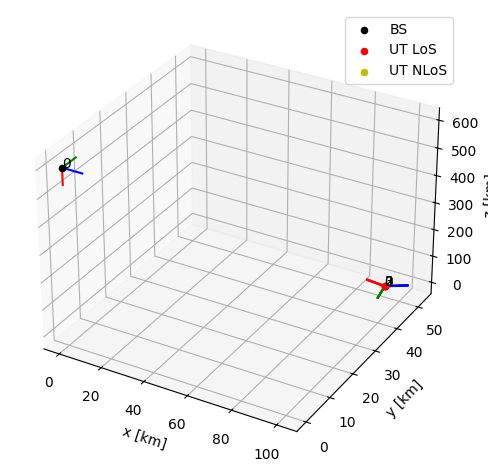

In [6]:
channel_model.show_topology()

First, it seems as if all UTs are on the same spot. However, this is just due to the scale. The UTs are dropped in a sector of a cell with an inter-site distance of 200 m, which is very small in comparison to the 600 km height of the satellite.
Next, we see that the users all point directly towards the satellite, while the satellite points directly to the ground. This is how the topology generator sets up every topology. TR 38.811 leaves the orientation of the UTs open; the satellite facing the nadir matches the calibration assumptions of TR 38.811 (Annex A, Table A-1), whose beam layout has a beam centered at the nadir of the satellite.
Additionally, we see that all UTs are either in LoS or Non Line of Sight (NLoS), without the indoor state. The models simulate outdoor UTs only: `set_topology` raises a `ValueError` for indoor UTs.

With the given topology we can now have a look at the actual model. This part will only briefly describe the inputs and outputs of the channel models without describing the actual mathematical model in great detail, as that would be way too complex for this notebook.

Just like the models in the terrestrial case, the NTN channels can be considered to be a multipath channel with each path being characterized by a complex valued gain (path coefficient) and delay (path delay). The path over which messages arrive first is considered to have a delay of 0, with every other delay being in relation to the first arriving path. Thus, the delay is not the absolute delay between transmission and reception, but the relative delay between paths. As we consider each user to possibly have multiple antennas, paths for each transmitter receiver antenna pair are simulated. The number of paths per pair depends on the simulation parameters but is equal for each pair in the same topology. Thus, there are a total of
number_of_transmitters * number_transmitter_antennas * number_receivers * number_receiver_antennas * number_paths_per_pair
paths per transmission. Additionally, the simulations might be over a consecutive number of time steps and each element of a batch, adding two more dimensions to this.

After defining a channel model and setting its topology, we can call it to sample Channel Impulse Responses (CIRs). To do that we call the model with the number of time steps (the number of samples in time) and the sampling frequency. We take 14 time steps at a sampling frequency of 14 MHz: the samples are 1/14 µs apart and span 13/14 µs, much less than one OFDM symbol, which lasts 1/(15 kHz) = 66.7 µs without its cyclic prefix at a subcarrier spacing of 15 kHz.

The models run eagerly in this notebook. On a GPU, `torch.compile` of the call of a model makes repeated calls faster; `set_topology` is then called outside the compiled function.

In [7]:
num_time_steps = 14
sampling_frequency = 14e6

# path_coefficients [batch size, num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps]
# path_delays [batch size, num_rx, num_tx, num_paths]
path_coefficients, path_delays = channel_model(num_time_steps, sampling_frequency)

# The paths of the link that the next figures show (batch example 0, the satellite and
# UT 0): their power over the antennas and the time steps
power = path_coefficients[0, 0, :, 0, :, :, :].abs().square().mean(dim=(0, 1, 3)).cpu()
with_power = power > 0
paths = torch.arange(power.numel())[with_power]
print(f"{power.numel()} paths, {int(with_power.sum())} of them with power")

8 paths, 7 of them with power


Now we can go ahead and visualize a few of these attributes. Let's start with the path coefficients. The path coefficient is a complex valued number, thus it has a certain amplitude and phase. When a symbol is transmitted, it will arrive over each path, with each path coefficient being multiplied with the symbol to add a phase shift and amplitude attenuation.

For the visualization, we plot the absolute value of the path coefficient for all paths of one Tx Rx antenna pair at one time step. Successive time steps will reuse the same paths and only introduce a phase rotation, so for the amplitude attenuation there is no need to consider more than one time step. The figures leave out the paths without power: a cluster more than 25 dB weaker than the strongest cluster of its link is removed (TR 38.901, clause 7.5, step 6), and its path keeps its place in the outputs with zero power.

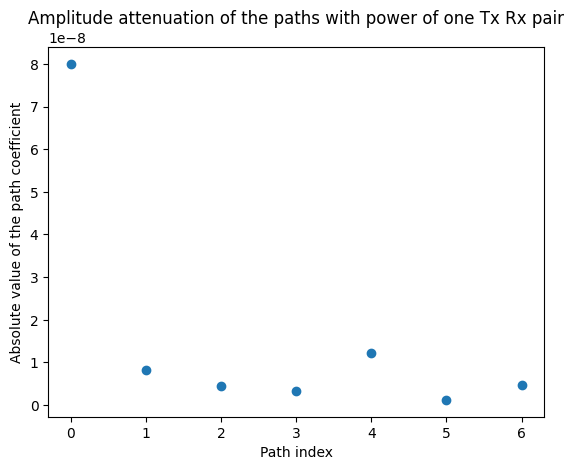

Power of the paths relative to the first path [dB]: 0.0, -15.9, -24.4, -24.4, -15.8, -29.2, -23.5, no power


In [8]:
amplitudes = path_coefficients[0, 0, 0, 0, 0, :, 0].abs().cpu()
plt.scatter(paths, amplitudes[with_power])
plt.xlabel("Path index")
plt.ylabel("Absolute value of the path coefficient")
plt.title("Amplitude attenuation of the paths with power of one Tx Rx pair")
plt.show()
relative = (power / power[0]).tolist()
print("Power of the paths relative to the first path [dB]: "
      + ", ".join(f"{10 * np.log10(p):.1f}" if p > 0 else "no power" for p in relative))

The model generates 8 paths per link; for this link, the first has a significantly higher amplitude than the others. With our given scenario at an elevation angle of 80 degrees, the LoS probability is 82.0 % (TR 38.811, Table 6.6.1-1). In both the LoS and NLoS case, the UTs will receive multiple paths. However, in the LoS case, the first path will represent the LoS component and the remaining paths represent additional reflections from the environment. The LoS component has high gain and arrives first. Thus, this first path is the LoS case. By changing the elevation angle to something smaller, such as 10 degrees, the reader can quickly generate a new topology with users more likely in NLoS, to see that the absolute value of the first path coefficient will be lower and closer to the others as well.

Next, let's have a look at the phases. First, we plot the same paths, but this time their position in the complex plane to visualize their phases as well.

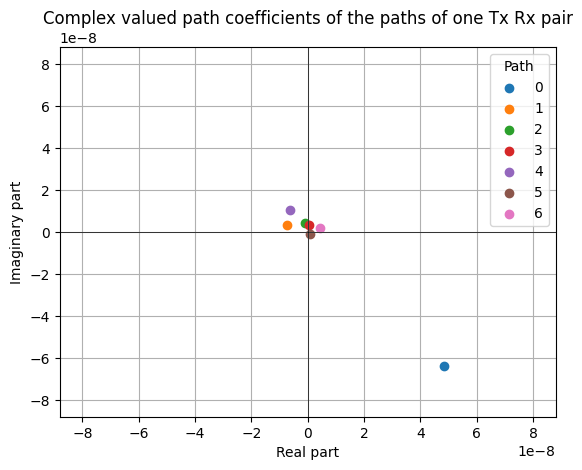

In [9]:
# The real and imaginary part of each path coefficient for one Tx Rx pair at one time step
coefficients = path_coefficients[0, 0, 0, 0, 0, :, 0].cpu()

# Plot each path with power individually and label it with its index
for i in paths.tolist():
    plt.scatter(coefficients[i].real, coefficients[i].imag, label=str(i))

plt.legend(title="Path")
# Adding x and y axes through the origin
plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)
plt.xlabel("Real part")
plt.ylabel("Imaginary part")
max_limit = coefficients.abs().max() * 1.1
plt.xlim(-max_limit, max_limit)
plt.ylim(-max_limit, max_limit)
plt.grid(True)
plt.title("Complex valued path coefficients of the paths of one Tx Rx pair")
plt.show()

As we can see, the first path again has the highest gain. The phases of all paths seem about random.

To finish the section on path coefficients, we will now visualize the path coefficient of a single path at subsequent time steps.

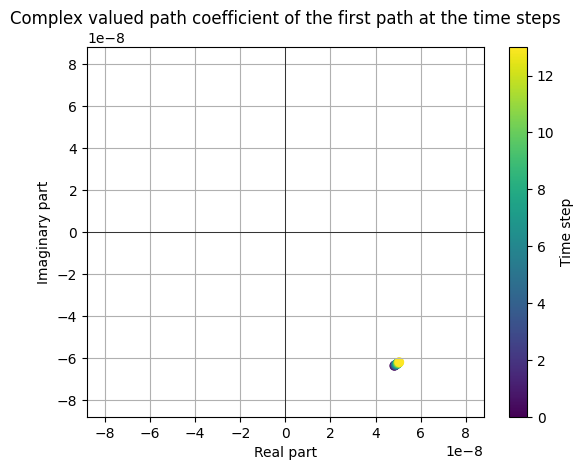

The phase of the first path changes over the 14 time steps by +0.0056 turns for this Tx Rx pair, by at most 0.0074 turns for the 128 links of the batch


In [10]:
def turns(coefficients):
    """The change of the phase over the time steps (last axis) [turns]"""
    phase = np.unwrap(torch.angle(coefficients).cpu().numpy(), axis=-1)
    return (phase[..., -1] - phase[..., 0]) / (2 * np.pi)


def show_time_steps(path_coefficients):
    """Plots the first path of one Tx Rx pair at its time steps"""
    samples = path_coefficients[0, 0, 0, 0, 0, 0, :].cpu()
    plt.scatter(samples.real, samples.imag, c=np.arange(samples.numel()), cmap="viridis")
    plt.colorbar(label="Time step")
    plt.axhline(0, color="black", linewidth=0.5)
    plt.axvline(0, color="black", linewidth=0.5)
    plt.xlabel("Real part")
    plt.ylabel("Imaginary part")
    max_limit = samples.abs().max() * 1.1
    plt.xlim(-max_limit, max_limit)
    plt.ylim(-max_limit, max_limit)
    plt.grid(True)
    plt.title("Complex valued path coefficient of the first path at the time steps")
    plt.show()
    # The first path of every UT at the first antenna of the satellite
    every_link = turns(path_coefficients[:, 0, 0, :, 0, 0, :])
    print(f"The phase of the first path changes over the {samples.numel()} time steps by "
          f"{turns(samples):+.4f} turns for this Tx Rx pair, by at most "
          f"{np.abs(every_link).max():.4f} turns for the {every_link.size} links of the batch")


show_time_steps(path_coefficients)

In this example, the samples lie close together, showing very little Doppler shift over the 13/14 µs that they span. However, one of the challenges of NTN is the potentially very significant Doppler shift. As the Doppler shift depends on the relative velocity of the satellite to the UT and on the UT movement, it will vary greatly with the UT positions and the orbits. A satellite in a low Earth orbit at 600 km moves at about 7.6 km/s, of which only a part lies along the line of sight to a UT at an elevation angle of 80 degrees. The models draw the direction of the orbit for each batch example, and the Doppler shift that the motion of the satellite causes is at most about 8 kHz at 2 GHz and 160 kHz at 40 GHz for a UT at 80 degrees. In the Ka band at 40 GHz, the phase of a path then turns by up to about 0.15 turns over the 13/14 µs of the samples, and about 160 turns over 1 ms. We visualize this in the following code block.

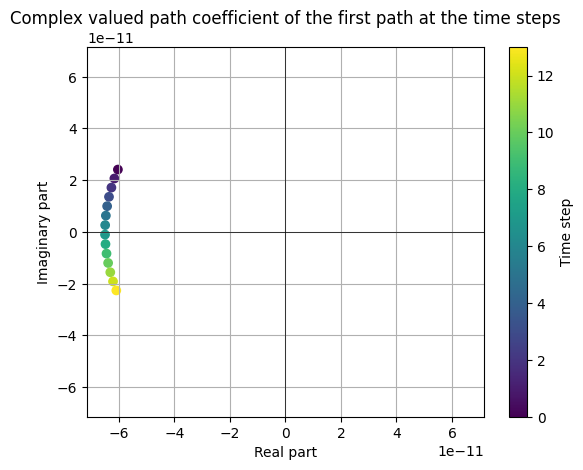

The phase of the first path changes over the 14 time steps by +0.1172 turns for this Tx Rx pair, by at most 0.1482 turns for the 128 links of the batch


In [11]:
def visualize_large_doppler_influence():
    carrier_frequency = 40e9
    ut_array = Antenna(polarization="single",
                       polarization_type="V",
                       antenna_pattern="omni",
                       carrier_frequency=carrier_frequency)

    # The satellite is the base station, so we name it bs
    bs_array = AntennaArray(num_rows=1,
                            num_cols=4,
                            polarization="dual",
                            polarization_type="VH",
                            antenna_pattern="38.901",
                            carrier_frequency=carrier_frequency)

    # We choose DenseUrban to match the scenario "dur" defined above
    channel_model = DenseUrban(carrier_frequency=carrier_frequency,
                               ut_array=ut_array,
                               bs_array=bs_array,
                               direction=direction,
                               elevation_angle=elevation_angle)

    # Generate the topology, with the UTs at the elevation angle of the model
    topology = gen_ntn_topology(batch_size=batch_size, num_ut=num_ut, scenario=scenario,
                                bs_height=satellite_height, elevation_angle=elevation_angle)

    # Set the topology
    channel_model.set_topology(*topology)

    num_time_steps = 14
    sampling_frequency = 14e6

    # path_coefficients [batch size, num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps]
    # path_delays [batch size, num_rx, num_tx, num_paths]
    path_coefficients, path_delays = channel_model(num_time_steps, sampling_frequency)

    show_time_steps(path_coefficients)


visualize_large_doppler_influence()

After investigating the path coefficients, we will now have a brief look at the path delays. The path delays are always generated together with the path coefficients. The path delays show the delay between multiple paths, with the first path always having a delay of 0 and the subsequent paths having a delay of a fraction of a microsecond here. Thus, they are not a measure of the absolute delay between transmission and reception, but rather a relative delay between each received path. The models give the delays in seconds; the figure shows them in microseconds.

Because the delays are assumed to be equal for each antenna of a transmitter or receiver, the path delays require fewer dimensions. Additionally, the paths are assumed to remain constant over the subsequent time steps, so that this dimension is also unnecessary. In total the path delays have a shape of [batch size, num_rx, num_tx, num_paths].

First, we will plot them similar to the absolute attenuation of the path coefficients before. Again, we plot the delay for each path with power of one transmitter receiver pair. For a better visualization, we will plot it both linearly and logarithmically; the logarithmic scale cannot show the delay 0 of the first path.

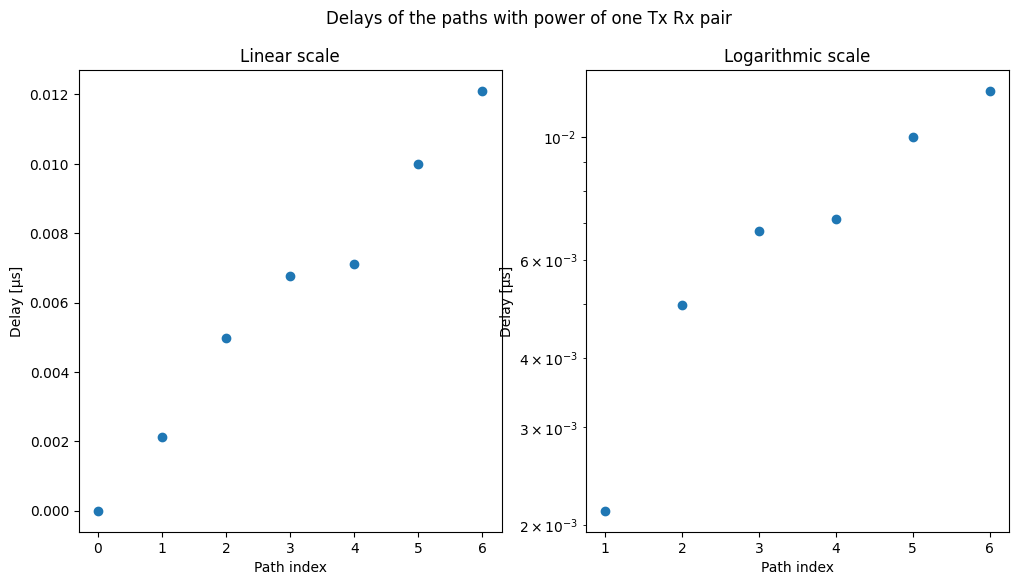

Delays of the paths with power [µs]: 0.0000, 0.0021, 0.0050, 0.0068, 0.0071, 0.0100, 0.0121
Delays of the paths without power [s]: 2.7288


In [12]:
# The delays of the paths with power of the link above [µs]
delays = path_delays[0, 0, 0, :].cpu()
delays_us = delays[with_power] * 1e6

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

# Linear scale
ax1.scatter(paths, delays_us)
ax1.set_xlabel("Path index")
ax1.set_ylabel("Delay [µs]")
ax1.set_title("Linear scale")

# Logarithmic scale, without the delay 0 of the first path
ax2.scatter(paths[delays_us > 0], delays_us[delays_us > 0])
ax2.set_yscale("log")
ax2.set_xlabel("Path index")
ax2.set_ylabel("Delay [µs]")
ax2.set_title("Logarithmic scale")

# Display the plots
plt.suptitle("Delays of the paths with power of one Tx Rx pair")
plt.show()
print("Delays of the paths with power [µs]: "
      + ", ".join(f"{d:.4f}" for d in delays_us.tolist()))
print("Delays of the paths without power [s]: "
      + (", ".join(f"{d:.4f}" for d in delays[~with_power].tolist()) or "none"))

We see the paths with power with their different delays. The first path has a delay of 0, and the other paths with power follow within about 0.01 µs. A path without power carries a placeholder delay that has no meaning (printed above, in seconds), which is why the figure leaves it out. These delays can be used in combination with the path coefficients to generate different channel model implementations.

One of these is the OFDM channel model, which takes an entire OFDM frame and simulates the channel attenuations on all symbols of the frame. Sionna already provides different functions we can use to do just that. In the following section, we will use the channel model to generate a new OFDM channel model, the same way we would do when using the terrestrial channel models from 3GPP TR 38.901 and their existing Sionna implementation. As there are already existing tutorials on the use of OFDM in Sionna, we will not explain each step in great detail.

In [13]:
# We are in uplink and each UT has only one antenna
num_streams_per_tx = 1

rg = ResourceGrid(num_ofdm_symbols=14,
                  fft_size=128,
                  subcarrier_spacing=30e3,
                  num_tx=num_ut,
                  num_streams_per_tx=num_streams_per_tx,
                  cyclic_prefix_length=20,
                  pilot_pattern="kronecker",
                  pilot_ofdm_symbol_indices=[2, 11])

# Function that calculates the subcarrier frequencies of the OFDM frame
frequencies = subcarrier_frequencies(rg.fft_size, rg.subcarrier_spacing)

# We need a realization of the channel impulse response to create the OFDM channel, so we
# sample an arbitrary realization.
cir = channel_model(1, 1)

# h is the channel response of the new OFDM channel. This incorporates both the path coefficients and
# path delays and results in only channel coefficients remaining by superpositioning the paths shifted
# with respect to their delay and the carrier frequency.
# h [batch size, num_rx, num_rx_ant, num_tx, num_tx_ant, num_time_steps, fft_size]
h = cir_to_ofdm_channel(frequencies, *cir, normalize=True)
# h_visualization [batch size, num_rx_ant, num_tx, fft_size]
h_visualization = torch.squeeze(h)

After generating h, we used torch.squeeze() to remove the dimensions of size 1. Next, we plot the real and imaginary components of the channel coefficient between one transmitter receiver pair for each subcarrier of the OFDM frame.

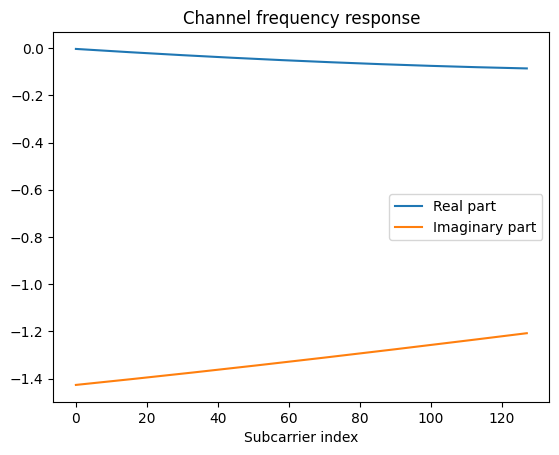

In [14]:
response = h_visualization[0, 0, 0, :].cpu()
plt.plot(response.real)
plt.plot(response.imag)
plt.legend(["Real part", "Imaginary part"])
plt.xlabel("Subcarrier index")
plt.title("Channel frequency response")
plt.show()

We can see a slight frequency selectivity in the given channel, but nothing that is too extreme. However, the result heavily depends on the elevation angle, carrier frequency and other parameters. Especially low elevation angles with high NLoS probabilities tend to have extreme frequency selectivity and small scale fading, making them hard to predict. To look at the channels of several users, we will use the condition number of the channel matrix between the antennas of the satellite and the UTs, the ratio of its largest to its smallest singular value. If the condition number is close to 1, the channels of the users are close to orthogonal and the users are easy to separate. If the condition number is high, the channels of the users are close to linearly dependent, making the equalization of the users very challenging.

We define the following function to compute the condition numbers of different channels and plot their cumulative distribution functions (CDFs).

In [15]:
# The batch sizes of the condition numbers
if mode == "reduced":
    cond_batch_size, cond_batch_size_num_ut = 64, 64
else:
    cond_batch_size, cond_batch_size_num_ut = 4096, 1024

MODELS = {"dur": DenseUrban, "sur": SubUrban, "urb": Urban}


def cond_numbers(scenario, elevation_angle=80.0, sat_height=600000.0, num_ut=2,
                 batch_size=1024, direction="uplink", carrier_frequency=2.0e9):
    """Returns the condition numbers of the channel frequency responses"""

    ut_array = Antenna(polarization="single",
                       polarization_type="V",
                       antenna_pattern="omni",
                       carrier_frequency=carrier_frequency)

    # The satellite will be the base station in our case
    bs_array = AntennaArray(num_rows=1,
                            num_cols=4,
                            polarization="dual",
                            polarization_type="VH",
                            antenna_pattern="38.901",
                            carrier_frequency=carrier_frequency)

    # Set up a CIR generator
    channel_model = MODELS[scenario](carrier_frequency=carrier_frequency,
                                     ut_array=ut_array,
                                     bs_array=bs_array,
                                     direction=direction,
                                     elevation_angle=elevation_angle,
                                     enable_pathloss=False,
                                     enable_shadow_fading=False)

    # The UTs at the elevation angle of the model
    topology = gen_ntn_topology(batch_size=batch_size, num_ut=num_ut, scenario=scenario,
                                bs_height=sat_height, elevation_angle=elevation_angle)

    # Set the topology
    channel_model.set_topology(*topology)

    # Generate random CIR realizations
    # As we need only a single sample in time, the sampling frequency does not matter.
    cir = channel_model(1, 1)

    # Compute the frequency response
    h = cir_to_ofdm_channel(frequencies, *cir, normalize=True)

    # [batch size, num_rx_ant, num_tx, fft_size] to [batch size, fft_size, num_rx_ant, num_tx]
    h = torch.permute(torch.squeeze(h), (0, 3, 1, 2))

    # Compute the condition numbers, one per batch example and subcarrier
    return torch.linalg.cond(h).reshape(-1).cpu().numpy()


def plot_cdf(c, label):
    """Plots the empirical CDF of the condition numbers c and prints their median"""
    c = np.sort(c)
    plt.plot(c, np.arange(1, c.size + 1) / c.size, label=label)
    print(f"{label}: median {np.median(c):.4g}")

DUR: median 4.281
SUR: median 8.464
URB: median 4.352


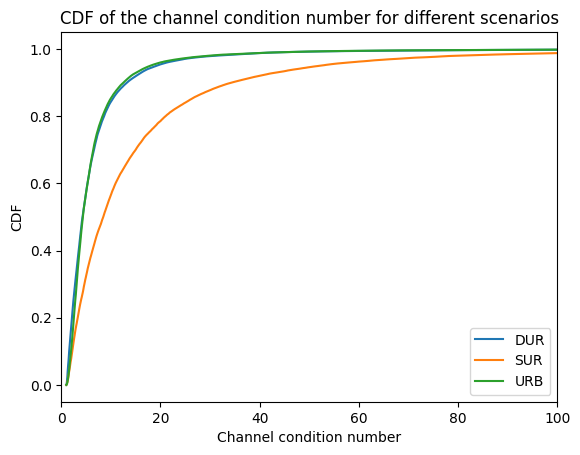

In [16]:
plt.figure()
for scenario, label in [("dur", "DUR"), ("sur", "SUR"), ("urb", "URB")]:
    plot_cdf(cond_numbers(scenario, batch_size=cond_batch_size), label)
plt.legend()
plt.xlim([0, 100])
plt.xlabel("Channel condition number")
plt.ylabel("CDF")
plt.title("CDF of the channel condition number for different scenarios")
plt.show()

As we can see, the dense urban scenario is best conditioned, closely followed by the urban scenario, and lastly we have the suburban scenario. However, besides the scenario, other parameters also influence the condition number. We will visualize them in the following cells.

First, we take the dense urban case but vary the height. A geostationary satellite is at 35 786 km.

600 km: median 4.258
1200 km: median 4.321
35 786 km: median 4.355


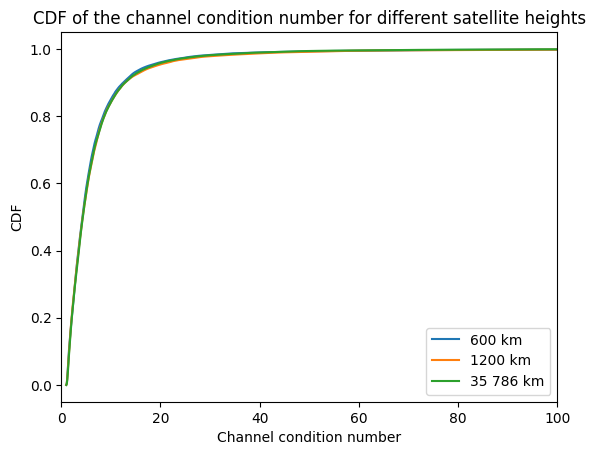

In [17]:
plt.figure()
for sat_height, label in [(600000.0, "600 km"), (1200000.0, "1200 km"),
                          (35786000.0, "35 786 km")]:
    plot_cdf(cond_numbers("dur", sat_height=sat_height, batch_size=cond_batch_size), label)
plt.legend()
plt.xlim([0, 100])
plt.xlabel("Channel condition number")
plt.ylabel("CDF")
plt.title("CDF of the channel condition number for different satellite heights")
plt.show()

As we can see, the height does not influence the channel condition number notably.

Next, we will change the elevation angle; the UTs are placed at the elevation angle of each model.

10°: median 5.543
30°: median 3.138
50°: median 3.051
70°: median 3.997
90°: median 2.433


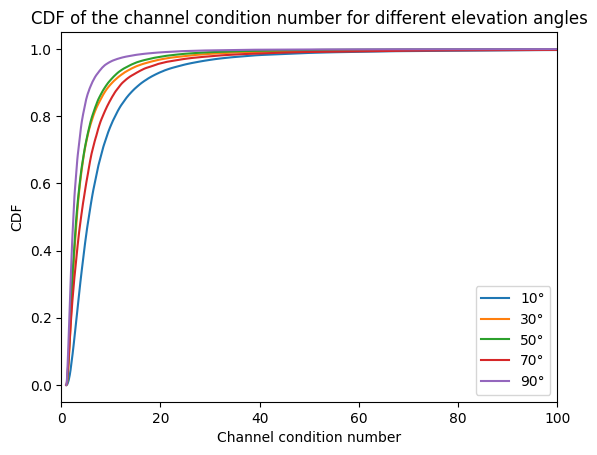

In [18]:
plt.figure()
for elevation_angle in [10.0, 30.0, 50.0, 70.0, 90.0]:
    plot_cdf(cond_numbers("dur", elevation_angle=elevation_angle, batch_size=cond_batch_size),
             f"{elevation_angle:.0f}°")
plt.legend()
plt.xlim([0, 100])
plt.xlabel("Channel condition number")
plt.ylabel("CDF")
plt.title("CDF of the channel condition number for different elevation angles")
plt.show()

In the graph, the elevation angle of 90 degrees has the best channel condition number and 10 degrees the worst, with the other elevation angles in between.

We do not vary the Doppler shift: the condition numbers are computed from one time sample at t = 0, where the Doppler shift multiplies every path by 1, so the condition number does not depend on it.

Next, we have a look at the number of UTs.

2 UTs: median 4.36
3 UTs: median 6033
4 UTs: median 3.448e+04


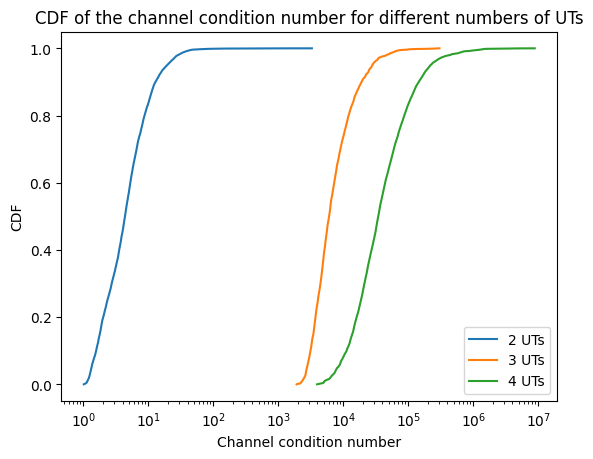

In [19]:
plt.figure()
for num_ut in [2, 3, 4]:
    plot_cdf(cond_numbers("dur", num_ut=num_ut, batch_size=cond_batch_size_num_ut),
             f"{num_ut} UTs")
plt.legend()
plt.xscale("log")
plt.xlabel("Channel condition number")
plt.ylabel("CDF")
plt.title("CDF of the channel condition number for different numbers of UTs")
plt.show()

As we can see, increasing the number of UTs very quickly degrades the channel condition number extremely. Therefore, scenarios with many UTs become very challenging very fast. Seen from the satellite, the UTs, up to about 200 m apart, lie in almost the same direction, and the satellite receives all paths of a UT from that direction: the models give the paths no angular spread at the satellite (TR 38.811, NOTE 8 of Tables 6.7.2-1a to 6.7.2-8b, which the models apply in both directions). The four columns of the satellite array then see all UTs with almost the same array response, and mainly the two polarizations of its elements tell the UTs apart.

Lastly, we vary the carrier frequency.

2 GHz: median 4.2
4 GHz: median 4.248
20 GHz: median 6.31
40 GHz: median 6.244


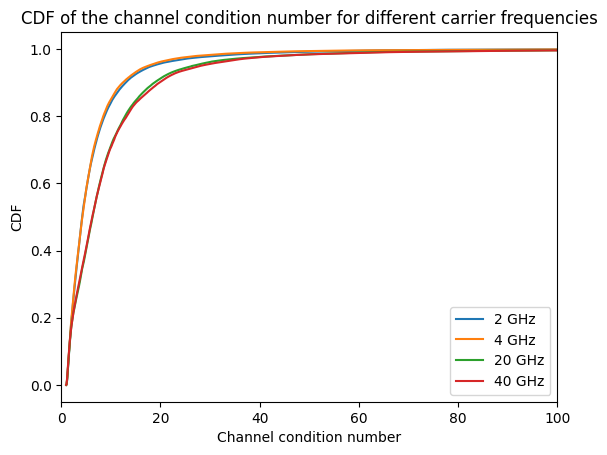

In [20]:
plt.figure()
for carrier_frequency, label in [(2e9, "2 GHz"), (4e9, "4 GHz"), (20e9, "20 GHz"),
                                 (40e9, "40 GHz")]:
    plot_cdf(cond_numbers("dur", carrier_frequency=carrier_frequency,
                          batch_size=cond_batch_size), label)
plt.legend()
plt.xlim([0, 100])
plt.xlabel("Channel condition number")
plt.ylabel("CDF")
plt.title("CDF of the channel condition number for different carrier frequencies")
plt.show()

As we can see, the carrier frequencies of the S band (2 GHz and 4 GHz) have better condition numbers than those of the Ka band (20 GHz and 40 GHz).

As a summary, we have looked at the NTN channel models of the 3GPP TR 38.811 standard. We have had a look at how to define the models and how to generate channel impulse responses with them. By visualizing the CIRs, we created an understanding of the resulting values and their meanings. Additionally, we have shown how to generate the common OFDM channel model for NTN cases. Finally, we had a look at how changing different parameters of the channel model influences the channel condition number, which showcased the channels' sensitivity to different parameters. In conclusion, the channels are well conditioned, as long as the number of users is small.